---
# **Do stocks cluster by sector, or by risk profile?**

Sector labels are assigned by index providers and used everywhere - in fund
construction, in portfolio diversification, in how people talk about markets.
This project tests whether they hold up empirically. If two stocks sit in the
same sector, do they actually behave alike?

Twenty US-listed equities are characterised on five risk and return measures,
then clustered using four algorithms. The resulting clusters are compared
against hand-assigned sector labels to see whether risk-based grouping recovers
sector membership or cuts across it.

**Data:** daily closing prices from the Yahoo Finance API, September 2016 to
September 2026.

---

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import yfinance as yf

from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans, DBSCAN, AgglomerativeClustering
from sklearn.metrics import (silhouette_score, davies_bouldin_score,
                             adjusted_rand_score)
from scipy.cluster.hierarchy import dendrogram, linkage
from pyclustering.cluster.kmedoids import kmedoids
from matplotlib.patches import Patch

import warnings
warnings.filterwarnings("ignore")

---
## **1. Data**

Twenty tickers were selected, five from each of four loosely defined groups.

| Group | Tickers |
| --- | --- |
| Big Tech | AAPL, AMZN, META, GOOGL, MSFT |
| Chips and EV | IBM, TSLA, NVDA, AMD, INTC |
| Pharma | LLY, MRK, NVO, AZN, PFE |
| Industrial | CVX, WM, BP, UUUU, RTX |

These groupings are hand-assigned rather than drawn from a standard
classification such as GICS, and some are deliberately loose - IBM sits
alongside TSLA and NVDA, and UUUU, a uranium miner, is grouped with an oil
major, a waste management firm and a defence contractor.

That looseness is part of the point. If risk-based clustering fails to recover
even a rough sector grouping, it raises the question of whether formal sector
labels describe how stocks actually behave or merely what business they are in.

A ten year window is used, September 2016 to September 2026, giving 2,514
trading days per ticker. Adjusted closing prices are used throughout, which
account for splits and dividends. The download returned complete data with no
missing values.

**A note on the window.** Ten years spans the COVID crash of March 2020, which
will dominate the maximum drawdown measure for most tickers. This is addressed
in the feature engineering section.

In [2]:
SECTORS = {
    "AAPL": "Big Tech",  "AMZN": "Big Tech",  "META": "Big Tech",
    "GOOGL": "Big Tech", "MSFT": "Big Tech",
    "IBM": "Chips/EV",   "TSLA": "Chips/EV",  "NVDA": "Chips/EV",
    "AMD": "Chips/EV",   "INTC": "Chips/EV",
    "LLY": "Pharma",     "MRK": "Pharma",     "NVO": "Pharma",
    "AZN": "Pharma",     "PFE": "Pharma",
    "CVX": "Industrial", "WM": "Industrial",  "BP": "Industrial",
    "UUUU": "Industrial","RTX": "Industrial",
}

TICKERS = list(SECTORS)

In [3]:
START_DATE = "2016-09-01"
END_DATE = "2026-09-01"

In [4]:
raw_prices = yf.download(TICKERS, start=START_DATE, end=END_DATE, 
                         auto_adjust=True)["Close"]

[*********************100%***********************]  20 of 20 completed


In [5]:
print(f"Shape of dataset: {raw_prices.shape}")
print(f"Null values in dataset: {raw_prices.isna().sum().sum()}")
raw_prices.head().round(2)

Shape of dataset: (2512, 20)
Null values in dataset: 0


Ticker,AAPL,AMD,AMZN,AZN,BP,CVX,GOOGL,IBM,INTC,LLY,META,MRK,MSFT,NVDA,NVO,PFE,RTX,TSLA,UUUU,WM
Date,,,,,,,,,,,,,,,,,,,,
2016-09-01,24.41,7.35,38.53,49.63,19.14,65.73,39.20,100.57,29.19,66.04,125.07,43.90,51.14,1.55,18.34,20.89,53.48,13.38,2.32,53.21
2016-09-02,24.64,7.51,38.62,50.71,19.61,66.20,39.47,100.58,29.23,65.72,125.41,43.96,51.21,1.53,18.13,20.94,53.58,13.19,2.34,53.50
2016-09-06,24.63,7.34,39.44,50.38,19.72,67.18,40.02,101.08,29.63,67.14,128.60,44.14,51.16,1.55,18.21,20.94,53.12,13.52,2.37,53.75
2016-09-07,24.78,6.84,39.22,50.51,19.76,67.48,40.02,101.90,29.54,67.20,129.91,43.88,51.20,1.53,18.17,20.99,53.04,13.45,2.34,53.64
2016-09-08,24.13,6.23,39.20,50.30,19.94,68.29,39.76,100.23,29.53,68.32,129.14,44.14,51.00,1.54,18.19,20.91,52.99,13.16,2.36,53.81


In [6]:
# Using the S&P500 as the market benchmark

daily_returns = raw_prices.pct_change().dropna()

sp500 = yf.download('^GSPC', start=START_DATE, end=END_DATE, auto_adjust=True)["Close"]
market_returns = sp500.pct_change().dropna()

[*********************100%***********************]  1 of 1 completed


---

## **2. Feature engineering**

Five measures characterise each stock:

| Feature | Definition |
| --- | --- |
| Annual return | Mean daily return annualised over 252 trading days |
| Annual volatility | Standard deviation of daily returns, annualised |
| Sharpe ratio | Excess return over a 3% risk-free rate, per unit of volatility |
| Beta | Covariance with the S&P 500 divided by market variance |
| Maximum drawdown | Largest peak-to-trough decline over the period |

### Does COVID dominate the drawdown measure?

A ten year window spans March 2020, raising the concern that maximum drawdown
would reduce to a single macro event rather than a durable risk characteristic.

Only 6 of 20 tickers hit their worst drawdown in 2020. The remainder are spread
across 2019, 2022, 2023, 2024, 2025 and 2026.

The timing is itself informative. Industrials bottomed in March 2020 - oil
collapse, aerospace shutdown. Big Tech and semiconductors bottomed in late 2022
during the rate-hiking cycle. Every pharma stock except AZN recorded its worst
drawdown in 2025 or 2026. Sector membership already appears to influence *when*
a stock falls, before any clustering is attempted.

### Feature correlation

The five features are correlated, some of it structural since the Sharpe ratio
is derived from return and volatility. Annual return correlates at 0.85 with
beta and 0.79 with volatility, reflecting the genuine relationship between risk
and reward rather than redundancy alone.

Sharpe ratio correlates at 0.80 with return but only 0.32 with volatility,
indicating it carries information neither component provides on its own. All
five are retained, with the correlation noted as a limitation.

### Do the sectors look coherent?

Comparing within-sector variation against overall variation gives an early
indication of whether these groupings describe stocks that behave alike. A
ratio below 1.0 means a sector is tighter than the market as a whole.

| Sector | Return | Volatility | Sharpe | Beta | Drawdown | Mean |
| --- | --- | --- | --- | --- | --- | --- |
| Big Tech | 0.16 | 0.33 | 0.61 | 0.15 | 0.99 | **0.45** |
| Pharma | 0.63 | 0.30 | 1.17 | 0.16 | 1.15 | **0.68** |
| Industrial | 0.83 | 1.49 | 0.48 | 0.87 | 1.08 | **0.95** |
| Chips/EV | 1.41 | 0.89 | 1.33 | 0.95 | 0.79 | **1.07** |

Only Big Tech is meaningfully tight, and it is tight on the measures that matter
most - 0.16 on return and 0.15 on beta. The five stocks move almost identically
relative to the market.

Chips/EV is **more internally varied than the market as a whole**. The label
carries negative information: knowing two stocks share it tells you less than
knowing nothing about them. IBM has a beta of 0.81 and a 12.5% annual return;
NVDA has a beta of 1.83 and 62.2%.

Pharma is tight on beta and volatility but loose on Sharpe and drawdown - the
stocks share a market-sensitivity profile while differing greatly in whether
they have delivered, with LLY returning 33.4% annually against PFE's 6.0%.

Industrial's spread is driven almost entirely by UUUU, a uranium miner with 73%
annualised volatility against WM's 20%.

This ordering is a prediction the clustering can test.

In [7]:
# Feature engineering

TRADING_DAYS = 252     # trading days in a year
RISK_FREE    = 0.03    # approximate 10-year US Treasury yield

features = pd.DataFrame(index=TICKERS)

# annualised mean return
features["Annual_Return"] = daily_returns.mean() * TRADING_DAYS

# annualised volatility
features["Annual_Volatility"] = daily_returns.std() * np.sqrt(TRADING_DAYS)

# Sharpe ratio - excess return per unit of risk
features["Sharpe_Ratio"] = (
    (features["Annual_Return"] - RISK_FREE) / features["Annual_Volatility"]
)

# beta - sensitivity to the S&P 500
common_idx = daily_returns.index.intersection(market_returns.index)
market_1d  = market_returns.loc[common_idx].squeeze()

for ticker in TICKERS:
    cov = np.cov(daily_returns.loc[common_idx, ticker].values, market_1d.values)
    features.loc[ticker, "Beta"] = cov[0, 1] / cov[1, 1]


def max_drawdown(returns):
    cum  = (1 + returns).cumprod()
    peak = cum.cummax()
    return ((cum - peak) / peak).min()


def max_drawdown_date(returns):
    cum  = (1 + returns).cumprod()
    peak = cum.cummax()
    return ((cum - peak) / peak).idxmin()


features["Max_Drawdown"] = [max_drawdown(daily_returns[t]) for t in TICKERS]
features["Sector"] = [SECTORS[t] for t in TICKERS]

print(features.round(3).to_string())

       Annual_Return  Annual_Volatility  Sharpe_Ratio   Beta  Max_Drawdown      Sector
AAPL           0.300              0.292         0.925  1.194        -0.385    Big Tech
AMZN           0.246              0.331         0.653  1.188        -0.561    Big Tech
META           0.230              0.392         0.511  1.320        -0.767    Big Tech
GOOGL          0.260              0.296         0.779  1.162        -0.443    Big Tech
MSFT           0.269              0.277         0.861  1.171        -0.371    Big Tech
IBM            0.125              0.282         0.338  0.813        -0.406    Chips/EV
TSLA           0.509              0.595         0.805  1.640        -0.736    Chips/EV
NVDA           0.622              0.501         1.183  1.827        -0.663    Chips/EV
AMD            0.579              0.571         0.963  1.771        -0.654    Chips/EV
INTC           0.216              0.455         0.408  1.382        -0.708    Chips/EV
LLY            0.334              0.306    

In [8]:
# Does COVID dominate the drawdown measure? 
# a ten year window spans March 2020. If every ticker's worst
# drawdown falls in that month, the measure captures a single
# event rather than a durable risk characteristic.

dd_dates = pd.Series(
    {t: max_drawdown_date(daily_returns[t]) for t in TICKERS}
).sort_values()

summary = pd.DataFrame({
    "Sector": [SECTORS[t] for t in dd_dates.index],
    "Worst drawdown": [f"{features.loc[t, 'Max_Drawdown']:.1%}" for t in dd_dates.index],
    "Occurred": dd_dates.dt.strftime("%b %Y"),
})

print(summary.to_string())
print(f"\nIn 2020: {(dd_dates.dt.year == 2020).sum()} of {len(TICKERS)}")
print(f"\nBy year:\n{dd_dates.dt.year.value_counts().sort_index().to_string()}")

           Sector Worst drawdown  Occurred
AAPL     Big Tech         -38.5%  Jan 2019
UUUU   Industrial         -79.2%  Mar 2020
WM     Industrial         -30.1%  Mar 2020
CVX    Industrial         -55.8%  Mar 2020
IBM      Chips/EV         -40.6%  Mar 2020
RTX    Industrial         -52.0%  Mar 2020
BP     Industrial         -63.9%  Oct 2020
NVDA     Chips/EV         -66.3%  Oct 2022
AMD      Chips/EV         -65.4%  Oct 2022
GOOGL    Big Tech         -44.3%  Nov 2022
META     Big Tech         -76.7%  Nov 2022
MSFT     Big Tech         -37.1%  Nov 2022
AMZN     Big Tech         -56.1%  Dec 2022
TSLA     Chips/EV         -73.6%  Jan 2023
AZN        Pharma         -27.9%  Nov 2024
INTC     Chips/EV         -70.8%  Apr 2025
PFE        Pharma         -59.0%  Apr 2025
MRK        Pharma         -43.4%  May 2025
LLY        Pharma         -34.5%  Aug 2025
NVO        Pharma         -74.7%  Mar 2026

In 2020: 6 of 20

By year:
2019    1
2020    6
2022    6
2023    1
2024    1
2025    4
2026    1

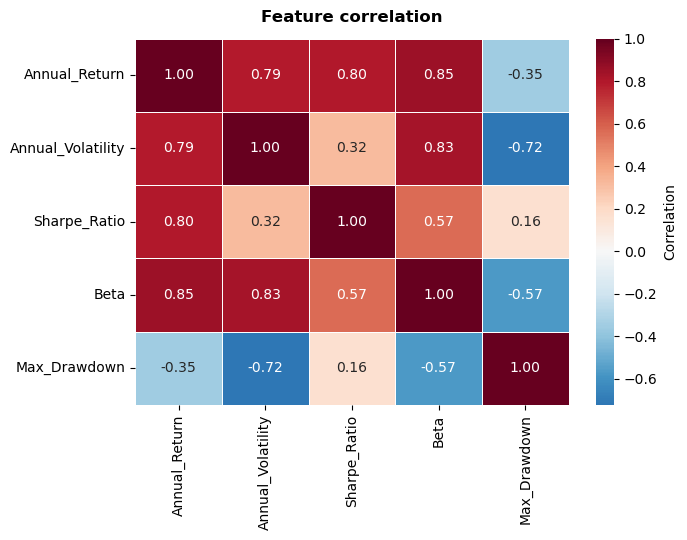

                   Annual_Return  Annual_Volatility  Sharpe_Ratio  Beta  Max_Drawdown
Annual_Return               1.00               0.79          0.80  0.85         -0.35
Annual_Volatility           0.79               1.00          0.32  0.83         -0.72
Sharpe_Ratio                0.80               0.32          1.00  0.57          0.16
Beta                        0.85               0.83          0.57  1.00         -0.57
Max_Drawdown               -0.35              -0.72          0.16 -0.57          1.00


In [9]:
# Feature redundancy
# Sharpe ratio is derived from annual return and volatility, so
# some correlation is structural. If it is near-perfect, the
# clustering effectively weights that dimension multiple times.

corr = features.drop(columns="Sector").corr()

fig, ax = plt.subplots(figsize=(7, 5.5))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="RdBu_r", center=0,
            linewidths=0.5, linecolor="white", ax=ax,
            cbar_kws={"label": "Correlation"})
ax.set_title("Feature correlation", fontsize=12, fontweight="bold", pad=12)
plt.tight_layout()
plt.show()

print(corr.round(2).to_string())

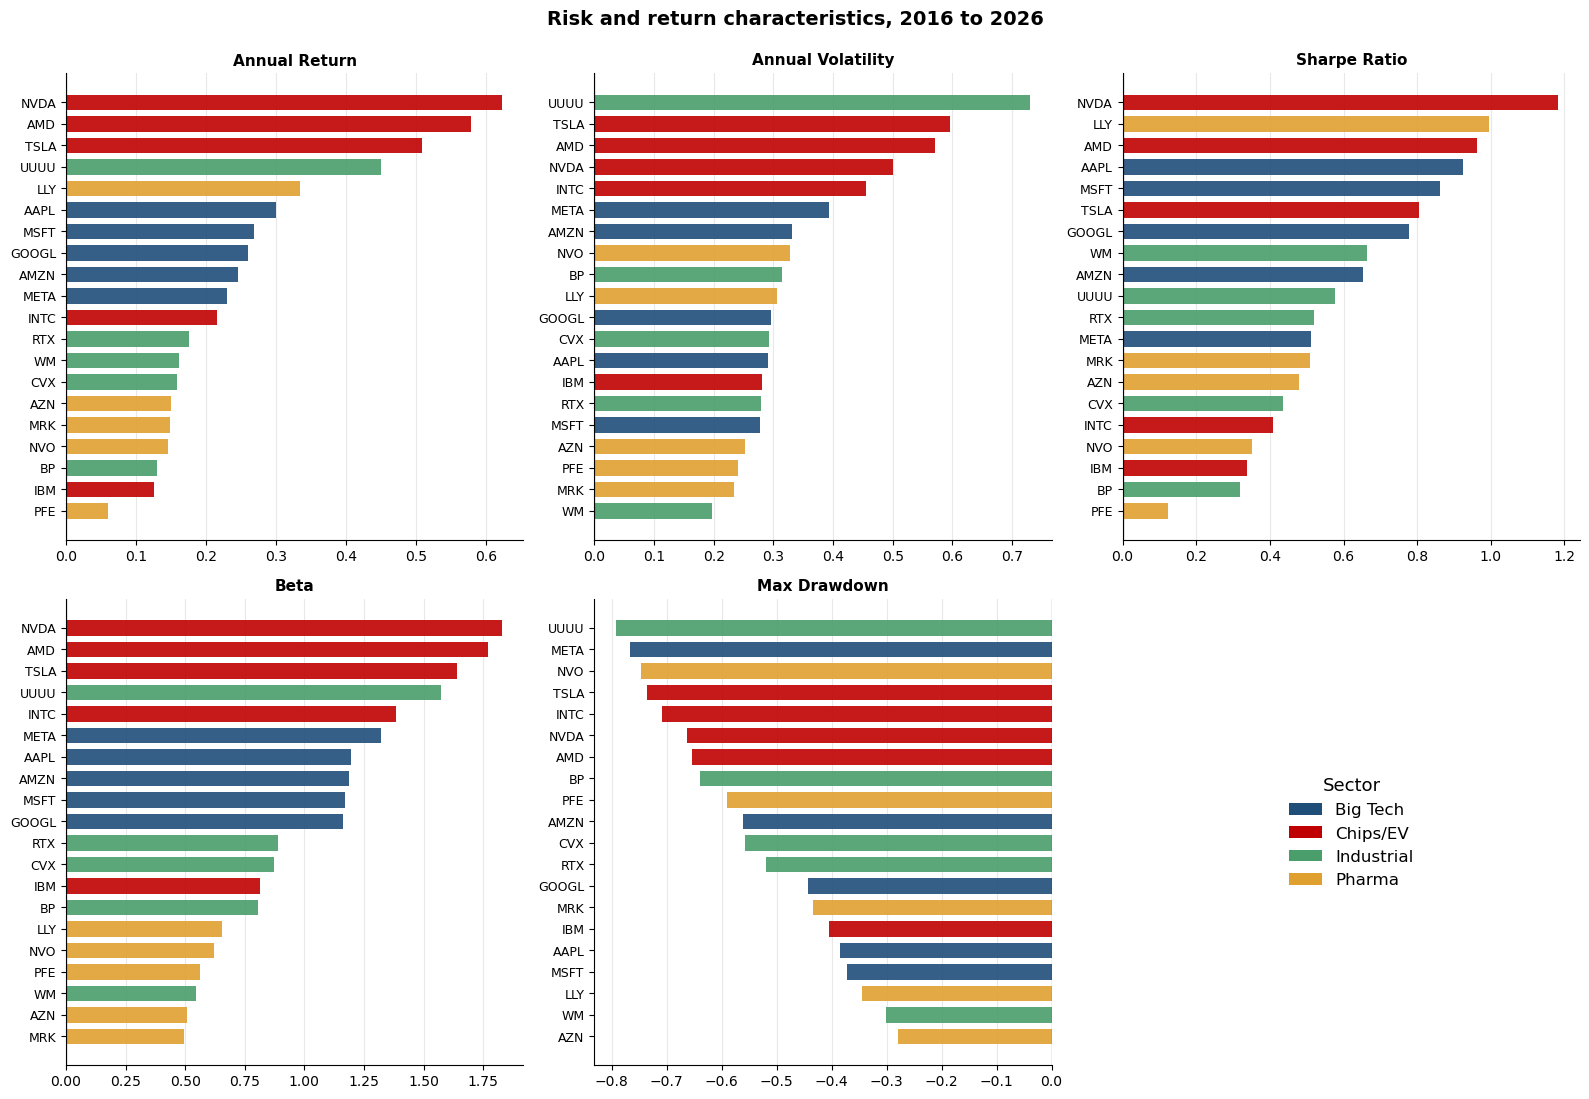

In [10]:
# Feature distributions by sector

feat_cols = [c for c in features.columns if c != "Sector"]
palette = dict(zip(["Big Tech", "Chips/EV", "Industrial", "Pharma"],
                   ["#1f4e79", "#c00000", "#4a9e6b", "#e0a030"]))

fig, axes = plt.subplots(2, 3, figsize=(16, 11))
axes = axes.flatten()

for ax, col in zip(axes, feat_cols):
    srt = features.sort_values(col, ascending=(col == "Max_Drawdown"))
    ax.barh(range(len(srt)), srt[col].values,
            color=[palette[s] for s in srt["Sector"]], alpha=0.9, height=0.72)
    ax.set_yticks(range(len(srt)))
    ax.set_yticklabels(srt.index, fontsize=9)
    ax.invert_yaxis()
    ax.set_title(col.replace("_", " "), fontsize=11, fontweight="bold")
    ax.axvline(0, color="black", linewidth=0.8)
    ax.grid(axis="x", color="#e8e8e8", linewidth=0.8)
    ax.set_axisbelow(True)
    for spine in ["top", "right"]:
        ax.spines[spine].set_visible(False)

# legend in the empty sixth panel
axes[-1].axis("off")
axes[-1].legend(
    handles=[Patch(facecolor=c, label=s) for s, c in palette.items()],
    loc="center", fontsize=12, frameon=False, title="Sector",
    title_fontsize=13,
)

fig.suptitle(f"Risk and return characteristics, {START_DATE[:4]} to {END_DATE[:4]}",
             fontsize=14, fontweight="bold", y=0.995)
plt.tight_layout()
plt.show()

In [11]:
# Do sectors look coherent?
# within-sector spread relative to overall spread. A sector whose
# members genuinely behave alike would show low internal variation.

overall = features[feat_cols].std()
within  = features.groupby("Sector")[feat_cols].std()

ratio = (within / overall).round(2)
ratio["Mean"] = ratio.mean(axis=1).round(2)

print("Within-sector standard deviation as a share of overall")
print("(below 1.0 means the sector is tighter than the market)\n")
print(ratio.sort_values("Mean").to_string())

Within-sector standard deviation as a share of overall
(below 1.0 means the sector is tighter than the market)

            Annual_Return  Annual_Volatility  Sharpe_Ratio  Beta  Max_Drawdown  Mean
Sector                                                                              
Big Tech             0.16               0.33          0.61  0.15          0.99  0.45
Pharma               0.63               0.30          1.17  0.16          1.15  0.68
Industrial           0.83               1.49          0.48  0.87          1.08  0.95
Chips/EV             1.41               0.89          1.33  0.95          0.79  1.07


In [12]:
# Scaling
# the features span very different ranges - Sharpe ratio sits near
# 1 while drawdown is a negative proportion - so distance-based
# clustering requires standardisation

scaler   = StandardScaler()
X        = scaler.fit_transform(features[feat_cols])
X_scaled = pd.DataFrame(X, index=TICKERS, columns=feat_cols)

print(X_scaled.describe().round(3).to_string())

       Annual_Return  Annual_Volatility  Sharpe_Ratio    Beta  Max_Drawdown
count         20.000             20.000        20.000  20.000        20.000
mean           0.000              0.000         0.000  -0.000        -0.000
std            1.026              1.026         1.026   1.026         1.026
min           -1.312             -1.175        -1.867  -1.309        -1.532
25%           -0.731             -0.578        -0.717  -0.949        -0.802
50%           -0.260             -0.421        -0.271  -0.054        -0.090
75%            0.289              0.365         0.749   0.673         0.895
max            2.313              2.715         2.120   1.830         1.651


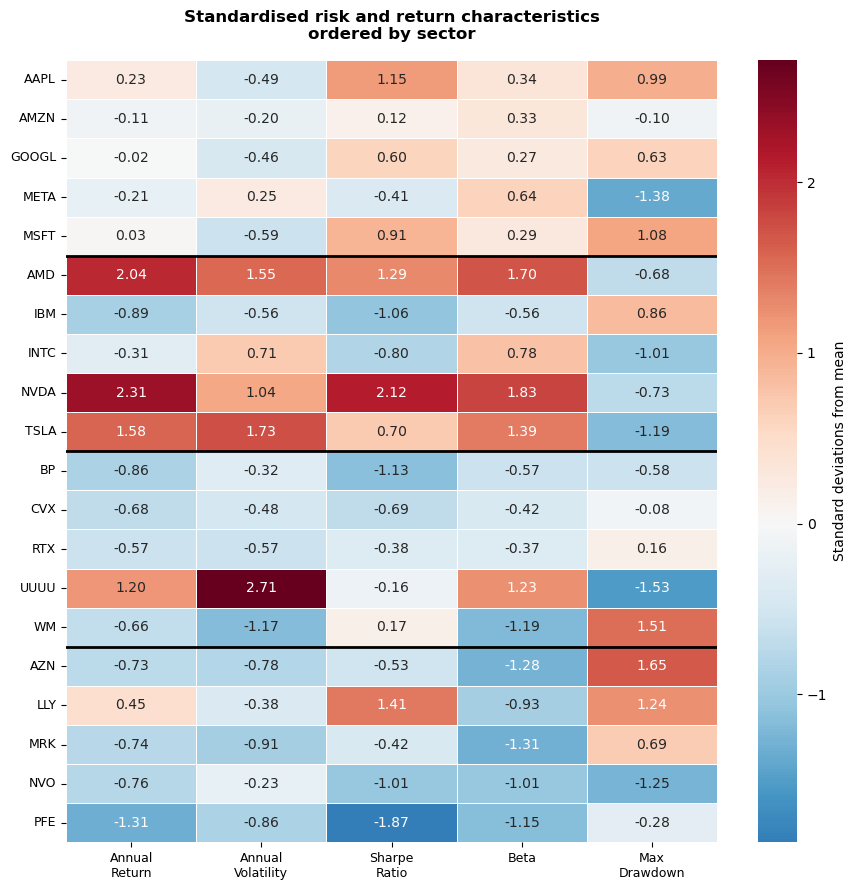

In [13]:
# Standardised feature heatmap 
# ordered by sector so any within-sector similarity is visible

order = sorted(TICKERS, key=lambda t: (SECTORS[t], t))

fig, ax = plt.subplots(figsize=(9, 9))
sns.heatmap(X_scaled.loc[order], annot=True, fmt=".2f",
            cmap="RdBu_r", center=0,
            linewidths=0.5, linecolor="white", ax=ax,
            cbar_kws={"label": "Standard deviations from mean"})

ax.set_title("Standardised risk and return characteristics\nordered by sector",
             fontsize=12, fontweight="bold", pad=15)
ax.set_xticklabels([c.replace("_", "\n") for c in feat_cols], fontsize=9)
ax.set_yticklabels(order, fontsize=9, rotation=0)
ax.set_xlabel("")
ax.set_ylabel("")

# sector dividers
boundaries = np.cumsum([sum(1 for t in order if SECTORS[t] == s)
                        for s in sorted(set(SECTORS.values()))])[:-1]
for b in boundaries:
    ax.axhline(b, color="black", linewidth=2)

plt.tight_layout()
plt.show()

---
## **3. Clustering**

Four algorithms are applied to the standardised feature matrix. Each works
differently, and agreement between them is stronger evidence than any single
result.

- **K-means** partitions around computed centroids, minimising within-cluster variance
- **Hierarchical (Ward)** merges the closest pair at each step, producing a full tree rather than a fixed partition
- **K-medoids** partitions around actual data points rather than computed centres, making it more robust to outliers and giving each cluster a representative stock
- **DBSCAN** groups by density, finding its own number of clusters and labelling sparse points as outliers instead of forcing them into a group

Cluster quality is measured by silhouette score and the Davies-Bouldin index.
The question the project asks, though, is answered by the **adjusted Rand
index** against sector membership - a value near 0 means the clustering is
unrelated to sector, near 1 that it recovers sectors exactly.


### Choosing k

Two criteria are in tension. The silhouette score prefers k=2, which would
separate the four highest-risk stocks from everything else. The research
question, however, asks whether clustering recovers four sectors, which argues
for k=4 so the comparison is like for like.

k=4 is used for the three partitioning algorithms throughout. The elbow curve
shows no sharp inflection, consistent with a dataset whose structure is
continuous rather than made up of well-separated groups.

  File "C:\Users\heffo\anaconda3\Lib\site-packages\joblib\externals\loky\backend\context.py", line 257, in _count_physical_cores
    cpu_info = subprocess.run(
               ^^^^^^^^^^^^^^^
  File "C:\Users\heffo\anaconda3\Lib\subprocess.py", line 548, in run
    with Popen(*popenargs, **kwargs) as process:
         ^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "C:\Users\heffo\anaconda3\Lib\subprocess.py", line 1026, in __init__
    self._execute_child(args, executable, preexec_fn, close_fds,
  File "C:\Users\heffo\anaconda3\Lib\subprocess.py", line 1538, in _execute_child
    hp, ht, pid, tid = _winapi.CreateProcess(executable, args,
                       ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^


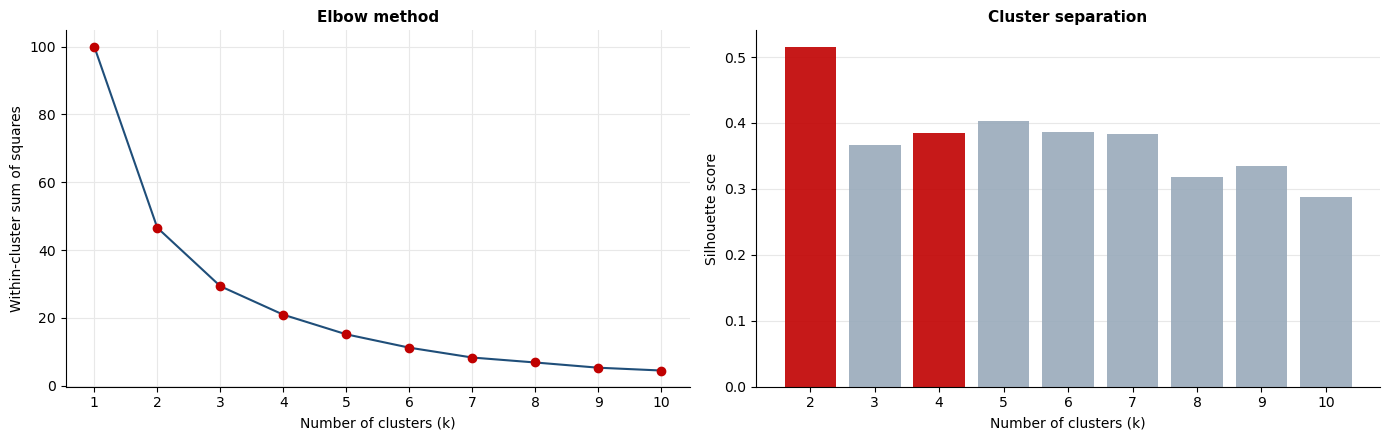

Silhouette by k:
  k = 2:  0.5147  <- highest
  k = 3:  0.3666
  k = 4:  0.3853
  k = 5:  0.4025
  k = 6:  0.3868
  k = 7:  0.3836
  k = 8:  0.3182
  k = 9:  0.3353
  k = 10:  0.2883


In [14]:
# Choosing k 
# two criteria are in tension. Silhouette measures how well
# separated the clusters are on their own terms. The research
# question, though, asks whether clusters recover four sectors,
# which argues for evaluating k=4 regardless of what silhouette
# prefers.

ssw = []
sil = {}
K_RANGE = range(1, 11)

for k in K_RANGE:
    km = KMeans(n_clusters=k, max_iter=300, n_init=10, random_state=38)
    labels = km.fit_predict(X_scaled)
    ssw.append(km.inertia_)
    if k >= 2:
        sil[k] = silhouette_score(X_scaled, labels)

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))

ax = axes[0]
ax.plot(K_RANGE, ssw, color="#1f4e79", linewidth=1.5, marker="o",
        markersize=6, markerfacecolor="#c00000", markeredgecolor="#c00000")
ax.set_xticks(K_RANGE)
ax.set_xlabel("Number of clusters (k)")
ax.set_ylabel("Within-cluster sum of squares")
ax.set_title("Elbow method", fontsize=11, fontweight="bold")
ax.grid(color="#e8e8e8", linewidth=0.8)
ax.set_axisbelow(True)

ax = axes[1]
ks, vals = list(sil), list(sil.values())
colours = ["#c00000" if k in (2, 4) else "#9ab" for k in ks]
ax.bar(ks, vals, color=colours, alpha=0.9)
ax.set_xticks(ks)
ax.set_xlabel("Number of clusters (k)")
ax.set_ylabel("Silhouette score")
ax.set_title("Cluster separation", fontsize=11, fontweight="bold")
ax.grid(axis="y", color="#e8e8e8", linewidth=0.8)
ax.set_axisbelow(True)

for ax in axes:
    for spine in ["top", "right"]:
        ax.spines[spine].set_visible(False)

plt.tight_layout()
plt.show()

print("Silhouette by k:")
for k, s in sil.items():
    flag = "  <- highest" if s == max(sil.values()) else ""
    print(f"  k = {k}:  {s:.4f}{flag}")

In [15]:
# k-means at k=2 and k=4 
# k=2 is what the data prefers; k=4 matches the number of sectors
# and allows a like-for-like comparison

sector_labels = [SECTORS[t] for t in TICKERS]
clusterings = {}

for k in (2, 4):
    km = KMeans(n_clusters=k, max_iter=300, n_init=10, random_state=38)
    clusterings[f"KMeans k={k}"] = km.fit_predict(X_scaled)

for name, labels in clusterings.items():
    print(f"\n{'=' * 60}\n{name}")
    print(f"  silhouette      {silhouette_score(X_scaled, labels):.3f}")
    print(f"  Davies-Bouldin  {davies_bouldin_score(X_scaled, labels):.3f}")
    print(f"  ARI vs sector   {adjusted_rand_score(sector_labels, labels):.3f}")
    print()
    print(pd.crosstab(
        pd.Series(sector_labels, index=TICKERS, name="Sector"),
        pd.Series(labels, index=TICKERS, name="Cluster"),
    ).to_string())


KMeans k=2
  silhouette      0.515
  Davies-Bouldin  0.625
  ARI vs sector   0.062

Cluster     0  1
Sector          
Big Tech    0  5
Chips/EV    3  2
Industrial  1  4
Pharma      0  5

KMeans k=4
  silhouette      0.385
  Davies-Bouldin  0.748
  ARI vs sector   0.070

Cluster     0  1  2  3
Sector                
Big Tech    0  2  3  0
Chips/EV    3  1  0  1
Industrial  1  3  0  1
Pharma      0  2  1  2


In [16]:
# which stocks are in the small k=2 cluster?
k2 = clusterings["KMeans k=2"]
small = min(set(k2), key=lambda c: (k2 == c).sum())
print("Small cluster:", sorted(t for t, l in zip(TICKERS, k2) if l == small))
print("\nProfile:")
print(features.loc[[t for t, l in zip(TICKERS, k2) if l == small]].round(3).to_string())

Small cluster: ['AMD', 'NVDA', 'TSLA', 'UUUU']

Profile:
      Annual_Return  Annual_Volatility  Sharpe_Ratio   Beta  Max_Drawdown      Sector
TSLA          0.509              0.595         0.805  1.640        -0.736    Chips/EV
NVDA          0.622              0.501         1.183  1.827        -0.663    Chips/EV
AMD           0.579              0.571         0.963  1.771        -0.654    Chips/EV
UUUU          0.450              0.730         0.576  1.571        -0.792  Industrial


In [17]:
# What defines each cluster? 

for name, labels in clusterings.items():
    prof = features.drop(columns="Sector").copy()
    prof["Cluster"] = labels
    summary = prof.groupby("Cluster").mean().round(3)
    summary["n"] = prof.groupby("Cluster").size()
    summary["Members"] = [
        ", ".join(sorted(t for t, l in zip(TICKERS, labels) if l == c))
        for c in sorted(set(labels))
    ]
    print(f"\n{name}")
    print(summary.to_string())


KMeans k=2
         Annual_Return  Annual_Volatility  Sharpe_Ratio   Beta  Max_Drawdown   n                                                                              Members
Cluster                                                                                                                                                              
0                0.540              0.599         0.882  1.702        -0.712   4                                                                AMD, NVDA, TSLA, UUUU
1                0.194              0.298         0.555  0.886        -0.503  16  AAPL, AMZN, AZN, BP, CVX, GOOGL, IBM, INTC, LLY, META, MRK, MSFT, NVO, PFE, RTX, WM

KMeans k=4
         Annual_Return  Annual_Volatility  Sharpe_Ratio   Beta  Max_Drawdown  n                                   Members
Cluster                                                                                                                  
0                0.540              0.599         0.882  1.702      

K-means at k=4 produces the following groups:

| Cluster | Members | Character |
| --- | --- | --- |
| 0 | AMD, NVDA, TSLA, UUUU | Highest return, highest volatility, beta above 1.7 |
| 1 | AMZN, BP, CVX, INTC, META, NVO, PFE, RTX | Middling returns, deeper drawdowns |
| 2 | AAPL, GOOGL, LLY, MSFT | High Sharpe, moderate beta, shallowest drawdowns |
| 3 | AZN, IBM, MRK, WM | Lowest beta and volatility, defensive |

None corresponds to a sector. Cluster 2 pairs three technology giants with a
pharmaceutical company, on the basis that all four have delivered efficient
returns without severe losses. Cluster 3 groups a technology firm, a waste
management company and two pharmaceutical firms by their common low market
sensitivity.

In [18]:
# Cluster visualisation 
# shared plotting function used by each algorithm section below.
# Two feature pairs plus a PCA projection, which captures 94% of
# the variance in two components.

CLUSTER_COLOURS = ["#c00000", "#1f4e79", "#4a9e6b", "#e0a030",
                   "#7b4fa0", "#8a8a8a"]


def plot_clusters(labels, title):
    labels = np.asarray(labels)
    uniq = sorted(set(labels))
    cmap = {c: CLUSTER_COLOURS[i % len(CLUSTER_COLOURS)]
            for i, c in enumerate(uniq)}

    pca = PCA(n_components=2)
    coords = pca.fit_transform(X_scaled.values)
    var = pca.explained_variance_ratio_

    fig = plt.figure(figsize=(14, 11))
    gs = fig.add_gridspec(2, 2, height_ratios=[1, 1.15], hspace=0.28, wspace=0.22)

    ax1 = fig.add_subplot(gs[0, 0])
    ax2 = fig.add_subplot(gs[0, 1])
    ax3 = fig.add_subplot(gs[1, :])

    for ax, xf, yf in [(ax1, "Annual_Return", "Annual_Volatility"),
                       (ax2, "Sharpe_Ratio", "Beta")]:
        for t, lab in zip(TICKERS, labels):
            ax.scatter(features.loc[t, xf], features.loc[t, yf],
                       color=cmap[lab], s=110, zorder=3,
                       edgecolors="white", linewidth=0.8)
            ax.annotate(t, (features.loc[t, xf], features.loc[t, yf]),
                        textcoords="offset points", xytext=(7, 4), fontsize=8)
        ax.set_xlabel(xf.replace("_", " "))
        ax.set_ylabel(yf.replace("_", " "))
        ax.set_title(f"{xf.replace('_', ' ')} vs {yf.replace('_', ' ')}",
                     fontsize=11, fontweight="bold")

    for (x, y), lab, t in zip(coords, labels, TICKERS):
        ax3.scatter(x, y, color=cmap[lab], s=140, zorder=3,
                    edgecolors="white", linewidth=0.9)
        ax3.annotate(t, (x, y), textcoords="offset points",
                     xytext=(8, 5), fontsize=9)
    ax3.set_xlabel(f"PC1 ({var[0]*100:.1f}% variance)")
    ax3.set_ylabel(f"PC2 ({var[1]*100:.1f}% variance)")
    ax3.set_title(f"PCA projection — {sum(var)*100:.1f}% of variance in two components",
                  fontsize=11, fontweight="bold")

    for ax in (ax1, ax2, ax3):
        ax.grid(color="#e8e8e8", linewidth=0.8, linestyle="--", alpha=0.7)
        ax.set_axisbelow(True)
        for spine in ["top", "right"]:
            ax.spines[spine].set_visible(False)

    handles = [Patch(facecolor=cmap[c], label=f"Cluster {c}") for c in uniq]
    fig.legend(handles=handles, loc="upper right", ncol=len(uniq),
               fontsize=10, bbox_to_anchor=(0.99, 1.005))
    fig.suptitle(title, fontsize=14, fontweight="bold", y=1.02)
    plt.show()

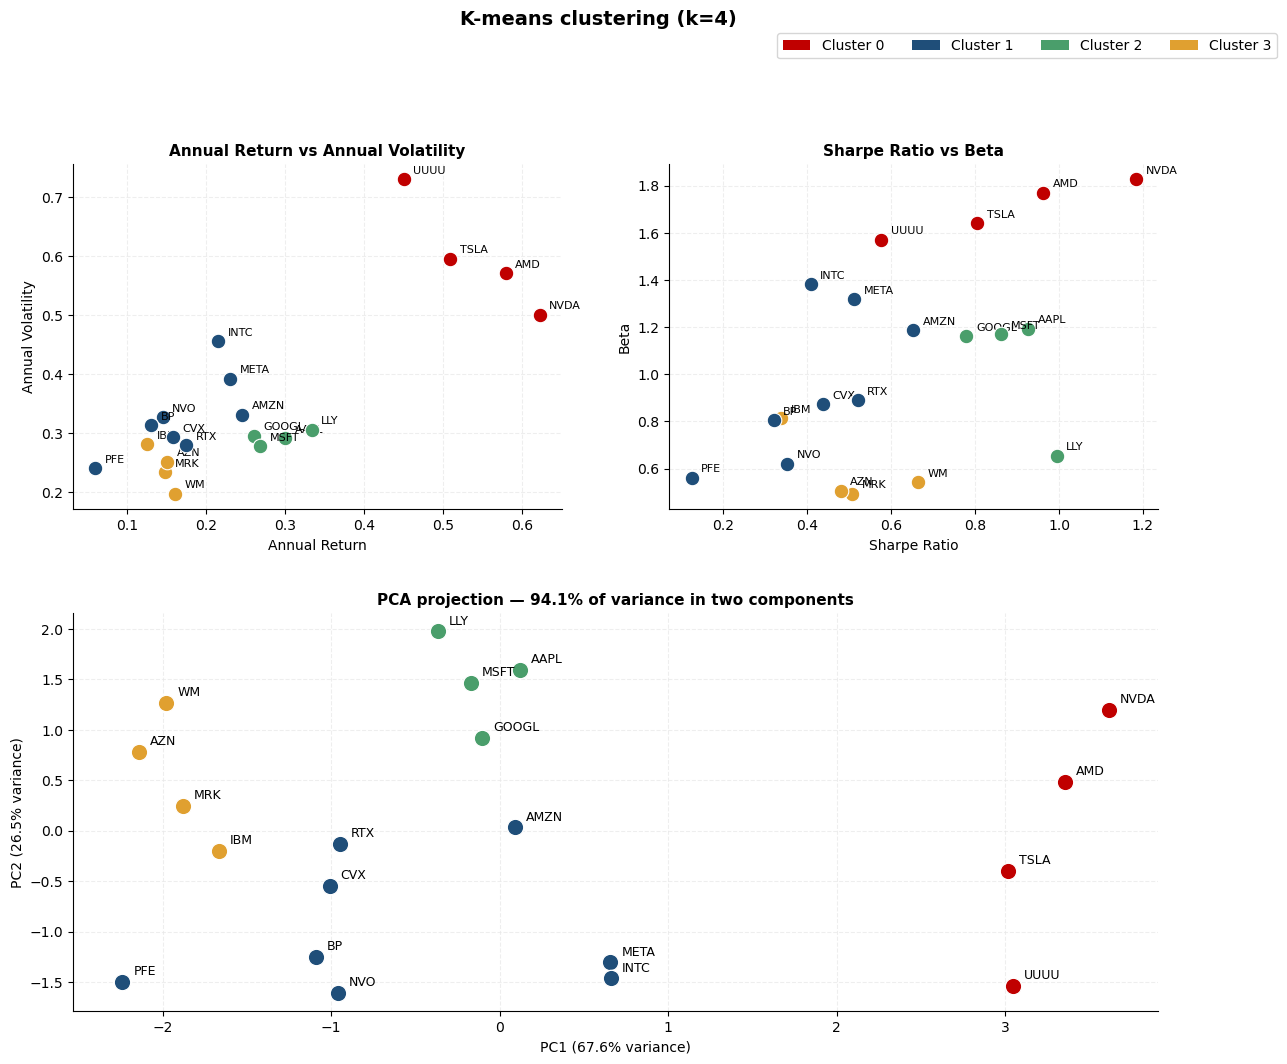

In [19]:
# ── K-means at k=4 ───────────────────────────────────────────────

K = 4
Xv = X_scaled.values

kmeans_labels = KMeans(n_clusters=K, n_init=10,
                       random_state=38).fit_predict(Xv)

plot_clusters(kmeans_labels, f"K-means clustering (k={K})")

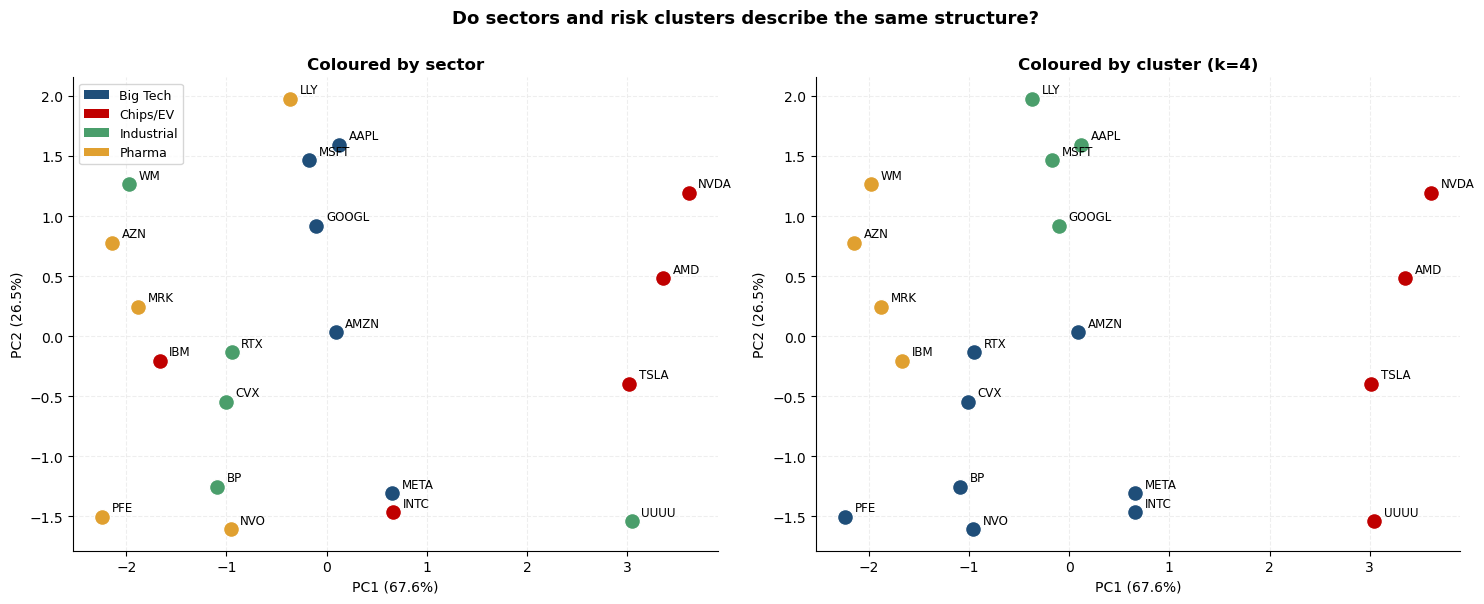

In [20]:
# The same projection, coloured by sector
# the comparison that answers the research question directly

pca = PCA(n_components=2)
coords = pca.fit_transform(X_scaled)
var = pca.explained_variance_ratio_

fig, axes = plt.subplots(1, 2, figsize=(15, 6))

sector_cmap = dict(zip(["Big Tech", "Chips/EV", "Industrial", "Pharma"],
                       ["#1f4e79", "#c00000", "#4a9e6b", "#e0a030"]))

for ax, (colouring, title) in zip(axes, [
    ([sector_cmap[SECTORS[t]] for t in TICKERS], "Coloured by sector"),
    ([CLUSTER_COLOURS[l] for l in clusterings["KMeans k=4"]], "Coloured by cluster (k=4)"),
]):
    for (x, y), col, t in zip(coords, colouring, TICKERS):
        ax.scatter(x, y, color=col, s=130, zorder=3,
                   edgecolors="white", linewidth=0.9)
        ax.annotate(t, (x, y), textcoords="offset points",
                    xytext=(7, 4), fontsize=8.5)
    ax.set_xlabel(f"PC1 ({var[0]*100:.1f}%)")
    ax.set_ylabel(f"PC2 ({var[1]*100:.1f}%)")
    ax.set_title(title, fontsize=12, fontweight="bold")
    ax.grid(color="#e8e8e8", linewidth=0.8, linestyle="--", alpha=0.7)
    ax.set_axisbelow(True)
    for spine in ["top", "right"]:
        ax.spines[spine].set_visible(False)

axes[0].legend(handles=[Patch(facecolor=c, label=s)
                        for s, c in sector_cmap.items()],
               fontsize=9, loc="upper left")

fig.suptitle("Do sectors and risk clusters describe the same structure?",
             fontsize=13, fontweight="bold", y=1.0)
plt.tight_layout()
plt.show()

In [21]:
loadings = pd.DataFrame(pca.components_.T, index=feat_cols,
                        columns=["PC1", "PC2"]).round(3)
print(loadings.to_string())

                     PC1    PC2
Annual_Return      0.514  0.249
Annual_Volatility  0.495 -0.260
Sharpe_Ratio       0.341  0.661
Beta               0.517 -0.015
Max_Drawdown      -0.328  0.659


### What the components mean

| Feature | PC1 | PC2 |
| --- | --- | --- |
| Annual return | 0.514 | 0.249 |
| Annual volatility | 0.495 | -0.260 |
| Sharpe ratio | 0.341 | 0.661 |
| Beta | 0.517 | -0.015 |
| Max drawdown | -0.328 | 0.659 |

**PC1 (66.7%) is market risk exposure.** Return, volatility and beta load
almost equally and positively, drawdown negatively. High values mean a stock
that moves hard with the market, delivers high returns and falls deeply.

**PC2 (26.3%) is risk-adjusted quality.** Sharpe ratio and drawdown load almost
identically at 0.66, while beta is near zero. Since drawdown is stored as a
negative, a high PC2 means efficient returns without severe losses - and it is
orthogonal to how much market risk was taken.

Together the two explain 93% of the variance in five features. The structure in
the data is genuinely two-dimensional: how much risk, and how well it was
rewarded.

Neither axis corresponds to sector. Pharma spans the full range of PC2, from LLY
at the top to NVO at the bottom. Big Tech spans it too, from MSFT to META.

---
### **Hierarchical clustering**

The dendrogram shows the full merge sequence rather than a single partition,
which makes it possible to see at what distance any two stocks first join.

Leaf labels are coloured by sector. If sector membership described genuine
similarity, stocks of the same colour would merge early and sit adjacent in the
tree.

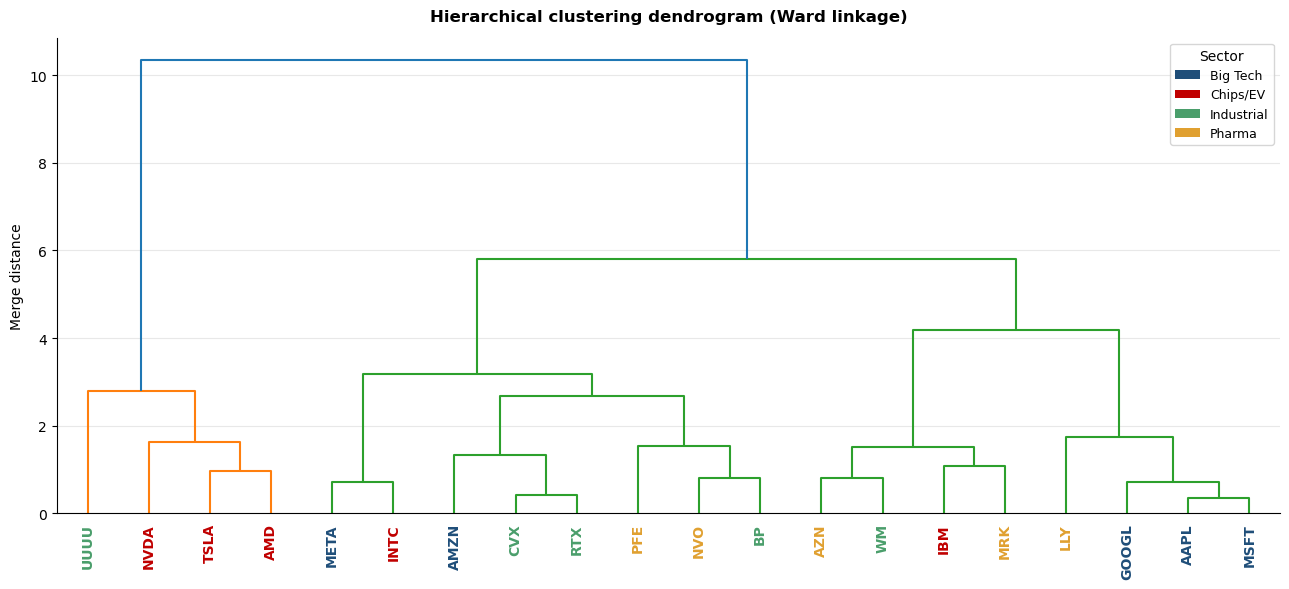

In [22]:
# Ward linkage minimises within-cluster variance at each merge.
# The dendrogram shows the full merge sequence, which reveals
# structure that a fixed k obscures.

linked = linkage(X_scaled.values, method="ward")

fig, ax = plt.subplots(figsize=(13, 6))
dendrogram(linked, labels=TICKERS, leaf_rotation=90, leaf_font_size=10,
           color_threshold=8, ax=ax)

ax.set_title("Hierarchical clustering dendrogram (Ward linkage)",
             fontsize=12, fontweight="bold", pad=12)
ax.set_xlabel("")
ax.set_ylabel("Merge distance")
ax.grid(axis="y", color="#e8e8e8", linewidth=0.8)
ax.set_axisbelow(True)
for spine in ["top", "right"]:
    ax.spines[spine].set_visible(False)

# colour the tick labels by sector to show where sectors sit in the tree
sector_cmap = dict(zip(["Big Tech", "Chips/EV", "Industrial", "Pharma"],
                       ["#1f4e79", "#c00000", "#4a9e6b", "#e0a030"]))
for tick in ax.get_xticklabels():
    tick.set_color(sector_cmap[SECTORS[tick.get_text()]])
    tick.set_fontweight("bold")

ax.legend(handles=[Patch(facecolor=c, label=s) for s, c in sector_cmap.items()],
          fontsize=9, loc="upper right", title="Sector")
plt.tight_layout()
plt.show()

They do not. Almost every early merge crosses a sector boundary.

The first merges are NVDA with TSLA and AMD, then META with INTC - a Big Tech
and a chip stock joining before either joins its own sector. CVX pairs with RTX,
PFE with NVO and then BP, AZN with WM, and IBM with MRK. That last pairing is
striking: IBM merges with a pharmaceutical company before it merges with any
other technology stock.

The right-hand branch ends with LLY joining GOOGL, AAPL and MSFT - a
pharmaceutical firm sitting inside a Big Tech grouping on risk characteristics.

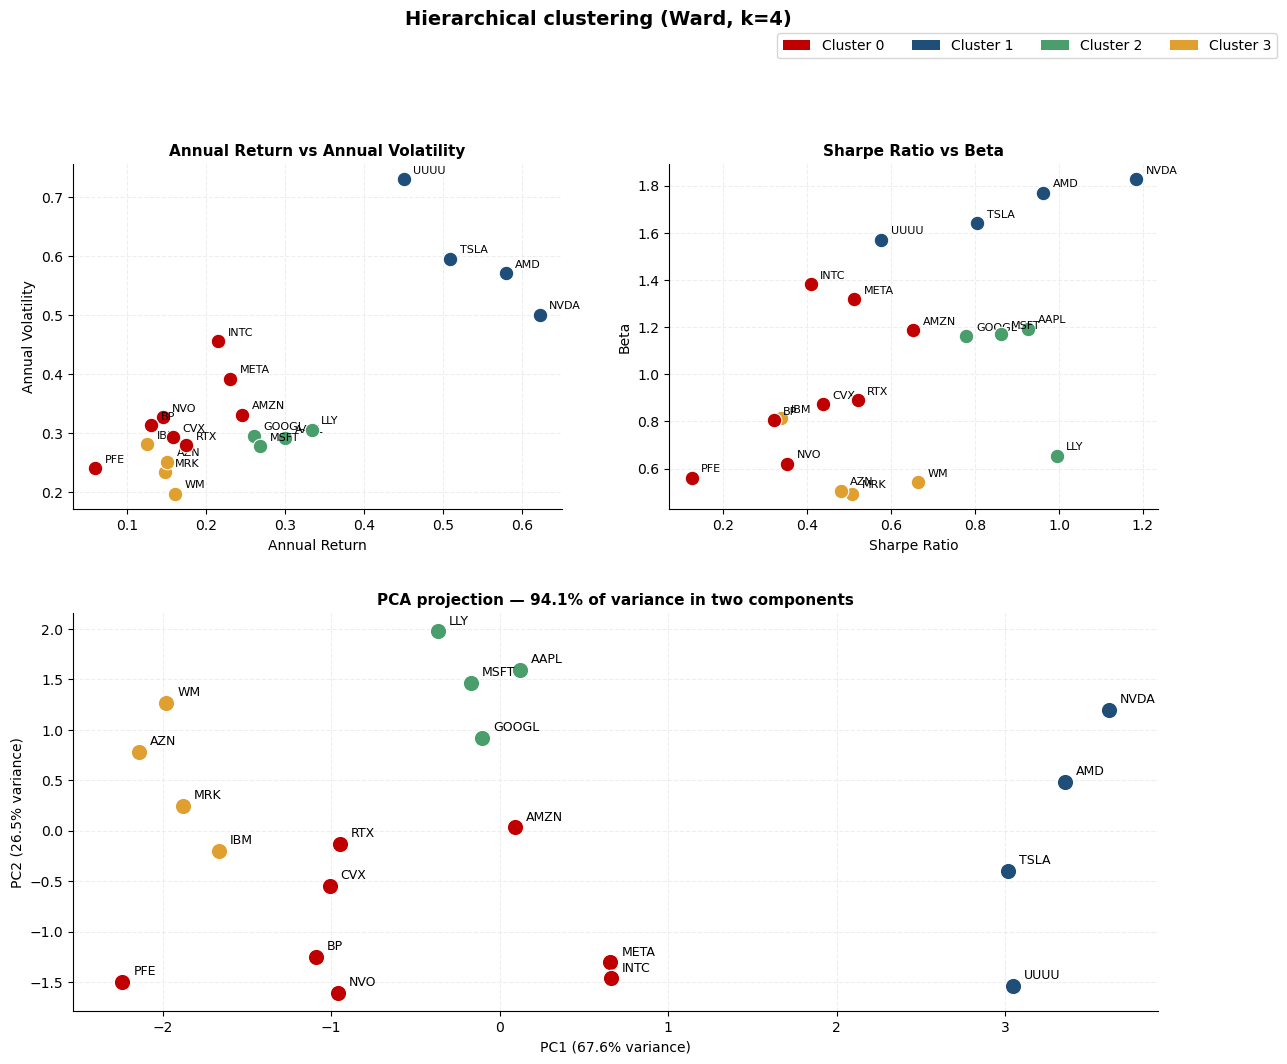

In [23]:
# Hierarchical at k=4 

hier = AgglomerativeClustering(n_clusters=K, metric="euclidean",
                               linkage="ward").fit_predict(X_scaled.values)

plot_clusters(hier, f"Hierarchical clustering (Ward, k={K})")

---
## **K-medoids**

K-medoids partitions around actual observations rather than computed centroids,
which makes it less sensitive to extreme values and gives each cluster a real
stock as its representative.

Initial medoids are seeded from the observations nearest the k-means centroids
rather than chosen arbitrarily, so the result does not depend on an unjustified
starting point.

Representative stock for each cluster: TSLA, BP, GOOGL, MRK


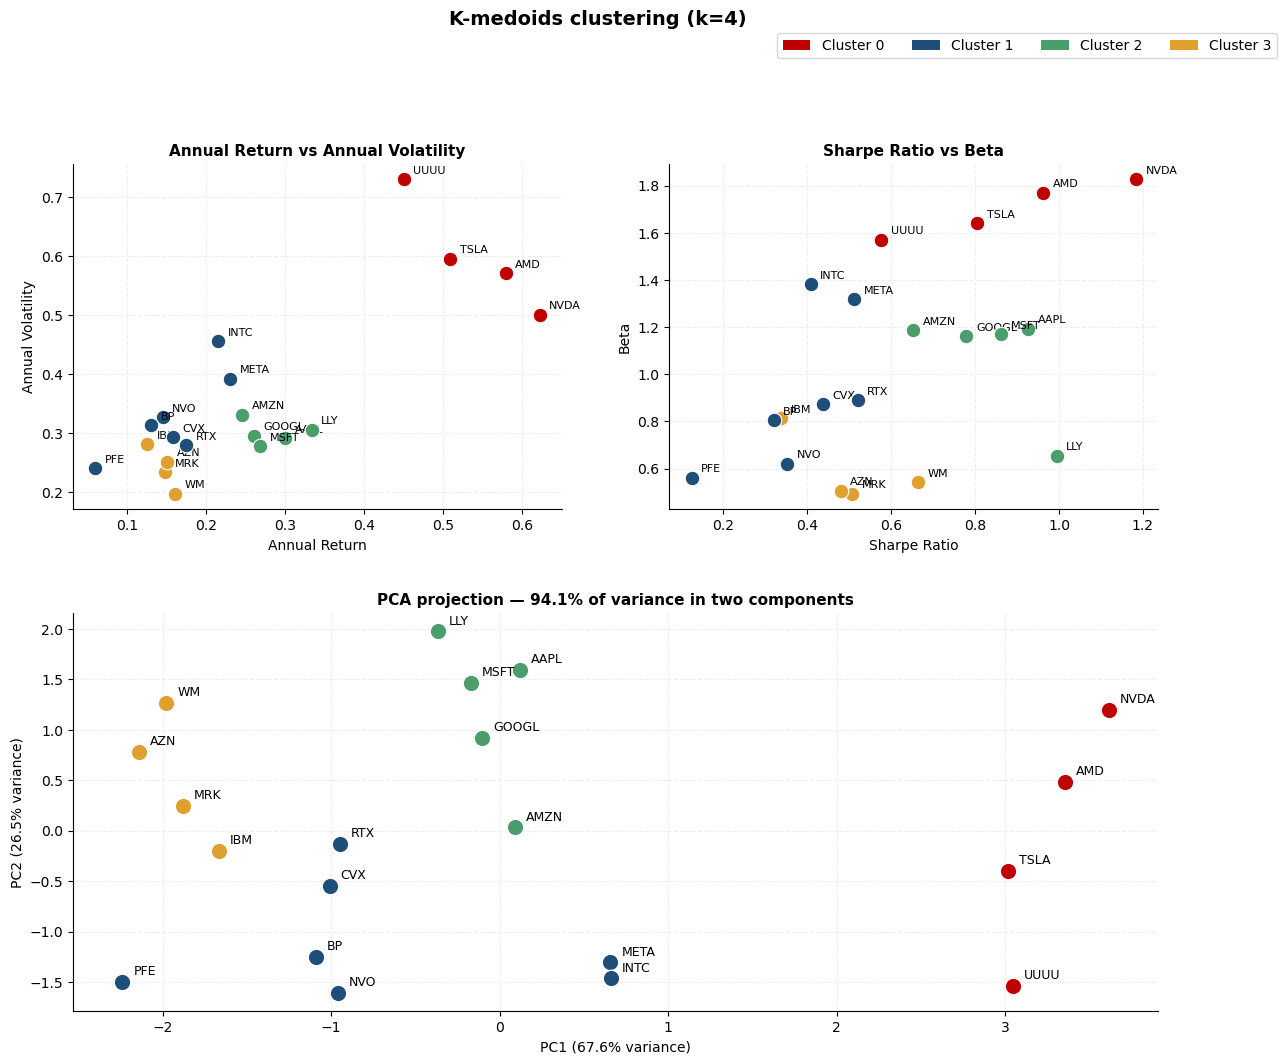

In [24]:
# medoids are actual data points rather than computed centroids,
# which makes clusters more robust to outliers and gives each one
# a representative stock. Seeded from the points nearest the
# k-means centroids rather than arbitrary indices.

km_seed = KMeans(n_clusters=K, n_init=10, random_state=38).fit(X_scaled.values)
seeds = [int(np.argmin(((X_scaled.values - c) ** 2).sum(axis=1)))
         for c in km_seed.cluster_centers_]

kmed = kmedoids(X_scaled.values, seeds)
kmed.process()

medoid_labels = np.zeros(len(TICKERS), dtype=int)
for cid, members in enumerate(kmed.get_clusters()):
    medoid_labels[members] = cid

medoid_tickers = [TICKERS[m] for m in kmed.get_medoids()]
print(f"Representative stock for each cluster: {', '.join(medoid_tickers)}")

plot_clusters(medoid_labels, f"K-medoids clustering (k={K})")

The four representative stocks are **TSLA, BP, GOOGL and MRK** - one from each
of four different sectors, which is itself a small illustration of the finding.

---
## **DBSCAN**

DBSCAN differs from the other three in two ways that matter here. It determines
its own number of clusters rather than being given one, and it can leave points
unassigned as outliers rather than forcing every stock into a group.

The `eps` parameter controls how close two points must be to count as
neighbours, and the result is sensitive to it. It is chosen from the k-distance
curve and then checked across a range of values.

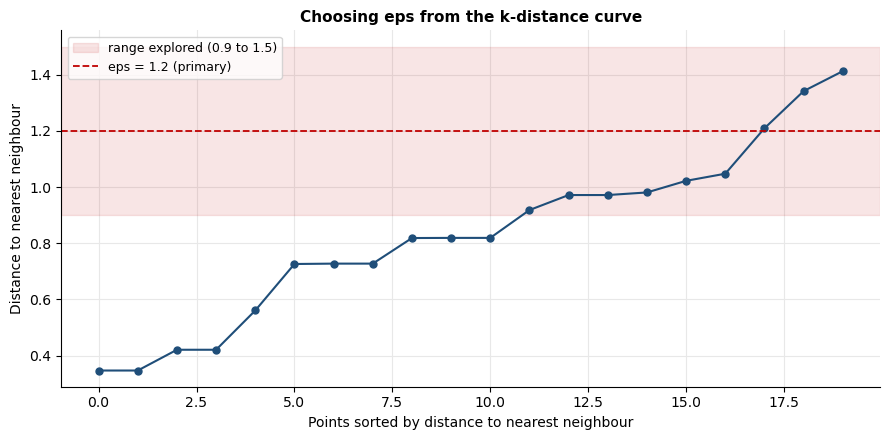

In [25]:
# density based, so it finds its own number of clusters and can
# label points as outliers rather than forcing them into a group.
# eps controls how close points must be to count as neighbours,
# and is chosen from the k-distance curve below.

from sklearn.neighbors import NearestNeighbors

MIN_SAMPLES = 2
EPS         = 1.2    # primary setting - see sensitivity analysis below

nn = NearestNeighbors(n_neighbors=MIN_SAMPLES).fit(X_scaled.values)
dists, _ = nn.kneighbors(X_scaled.values)
kdist = np.sort(dists[:, -1])

fig, ax = plt.subplots(figsize=(9, 4.5))
ax.plot(range(len(kdist)), kdist, color="#1f4e79", linewidth=1.5,
        marker="o", markersize=5)
ax.axhspan(0.9, 1.5, color="#c00000", alpha=0.10,
           label="range explored (0.9 to 1.5)")
ax.axhline(EPS, color="#c00000", linestyle="--", linewidth=1.3,
           label=f"eps = {EPS} (primary)")

ax.set_xlabel("Points sorted by distance to nearest neighbour")
ax.set_ylabel("Distance to nearest neighbour")
ax.set_title("Choosing eps from the k-distance curve",
             fontsize=11, fontweight="bold")
ax.legend(fontsize=9, loc="upper left")
ax.grid(color="#e8e8e8", linewidth=0.8)
ax.set_axisbelow(True)
for spine in ["top", "right"]:
    ax.spines[spine].set_visible(False)
plt.tight_layout()
plt.show()

In [26]:
# DBSCAN at the primary setting

db = DBSCAN(eps=EPS, min_samples=MIN_SAMPLES).fit_predict(X_scaled.values)

n_clusters = len(set(db) - {-1})
outliers   = [t for t, l in zip(TICKERS, db) if l == -1]

print(f"eps = {EPS}, min_samples = {MIN_SAMPLES}")
print(f"Clusters found: {n_clusters}")
print(f"Outliers ({len(outliers)}): {', '.join(outliers) if outliers else 'none'}")
print()
print(pd.crosstab(
    pd.Series(sector_labels, index=TICKERS, name="Sector"),
    pd.Series(db, index=TICKERS, name="Cluster"),
).to_string())

eps = 1.2, min_samples = 2
Clusters found: 3
Outliers (3): LLY, PFE, UUUU

Cluster     -1   0   1   2
Sector                    
Big Tech     0   4   1   0
Chips/EV     0   1   1   3
Industrial   1   4   0   0
Pharma       2   3   0   0


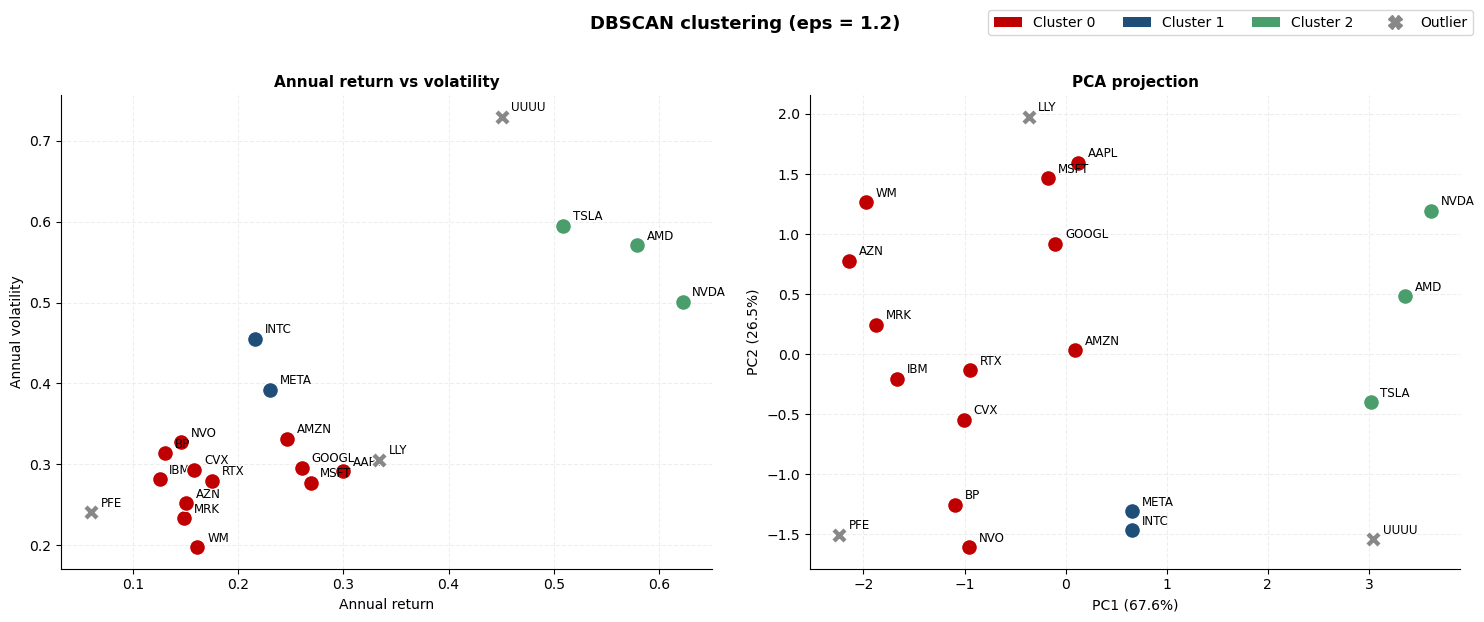

In [27]:
# DBSCAN visualisation 
# outliers shown as crosses rather than dropped, since which
# stocks fail to join a cluster is itself informative

pca    = PCA(n_components=2)
coords = pca.fit_transform(X_scaled.values)
var    = pca.explained_variance_ratio_

db_cmap = {c: CLUSTER_COLOURS[i % len(CLUSTER_COLOURS)]
           for i, c in enumerate(sorted(set(db) - {-1}))}
db_cmap[-1] = "#888888"

fig, axes = plt.subplots(1, 2, figsize=(15, 6))

for i, (t, lab) in enumerate(zip(TICKERS, db)):
    axes[0].scatter(features.loc[t, "Annual_Return"],
                    features.loc[t, "Annual_Volatility"],
                    color=db_cmap[lab], s=130, zorder=3,
                    marker="X" if lab == -1 else "o",
                    edgecolors="white", linewidth=0.9)
    axes[0].annotate(t, (features.loc[t, "Annual_Return"],
                         features.loc[t, "Annual_Volatility"]),
                     textcoords="offset points", xytext=(7, 4), fontsize=8.5)

    axes[1].scatter(coords[i, 0], coords[i, 1],
                    color=db_cmap[lab], s=130, zorder=3,
                    marker="X" if lab == -1 else "o",
                    edgecolors="white", linewidth=0.9)
    axes[1].annotate(t, (coords[i, 0], coords[i, 1]),
                     textcoords="offset points", xytext=(7, 4), fontsize=8.5)

axes[0].set_xlabel("Annual return")
axes[0].set_ylabel("Annual volatility")
axes[0].set_title("Annual return vs volatility", fontsize=11, fontweight="bold")

axes[1].set_xlabel(f"PC1 ({var[0]*100:.1f}%)")
axes[1].set_ylabel(f"PC2 ({var[1]*100:.1f}%)")
axes[1].set_title("PCA projection", fontsize=11, fontweight="bold")

for ax in axes:
    ax.grid(color="#e8e8e8", linewidth=0.8, linestyle="--", alpha=0.7)
    ax.set_axisbelow(True)
    for spine in ["top", "right"]:
        ax.spines[spine].set_visible(False)

handles = [Patch(facecolor=db_cmap[c], label=f"Cluster {c}")
           for c in sorted(set(db) - {-1})]
if -1 in db:
    handles.append(plt.Line2D([0], [0], marker="X", color="#888888",
                              markersize=10, linestyle="None", label="Outlier"))
fig.legend(handles=handles, loc="upper right", ncol=len(handles),
           fontsize=10, bbox_to_anchor=(0.99, 1.04))
fig.suptitle(f"DBSCAN clustering (eps = {EPS})",
             fontsize=13, fontweight="bold", y=1.02)
plt.tight_layout()
plt.show()

In [28]:
# Sensitivity to eps 
# DBSCAN's output depends heavily on eps, so the conclusion should
# be checked across a range rather than resting on one value.
#
# Note that ARI is computed only on stocks assigned to a cluster.
# At tight eps most stocks are classified as outliers, so the
# metric is computed on a small surviving subset and is not
# comparable to values computed on the full sample.

rows = []
for eps in [0.7, 0.8, 0.9, 1.0, 1.2, 1.5]:
    lab    = DBSCAN(eps=eps, min_samples=MIN_SAMPLES).fit_predict(X_scaled.values)
    mask   = lab != -1
    n_kept = int(mask.sum())
    n      = len(set(lab[mask]))
    rows.append({
        "eps": eps,
        "clusters": n,
        "retained": n_kept,
        "outliers": int((~mask).sum()),
        "silhouette": round(silhouette_score(X_scaled.values[mask], lab[mask]), 3)
                      if n > 1 else np.nan,
        "ARI vs sector": round(adjusted_rand_score(
            np.array(sector_labels)[mask], lab[mask]), 3) if n > 1 else np.nan,
        "sample": "usable" if n_kept >= 15 else "too small to interpret",
    })

print(pd.DataFrame(rows).to_string(index=False))

 eps  clusters  retained  outliers  silhouette  ARI vs sector                 sample
 0.7         2         5        15       0.739          1.000 too small to interpret
 0.8         3         8        12       0.658          0.652 too small to interpret
 0.9         4        11         9       0.598          0.362 too small to interpret
 1.0         5        15         5       0.529          0.467                 usable
 1.2         3        17         3       0.366          0.089                 usable
 1.5         2        20         0       0.515          0.062                 usable


The sensitivity analysis needs reading carefully. At tight `eps` values the ARI
against sector rises sharply - reaching 1.000 at eps=0.7 - but only 5 of 20
stocks remain assigned at that setting. The metric is computed on whatever
survives, so a high value on a collapsed sample measures the collapse rather
than genuine agreement.

On the settings that retain enough data to interpret, ARI stays low: 0.089 at
eps=1.2 with 17 stocks, and 0.062 at eps=1.5 with all 20. The conclusion does
not depend on the choice of `eps`.

At eps=1.2 the outliers are **LLY, PFE and UUUU** - the two pharmaceutical
stocks at opposite extremes of risk-adjusted performance, and a uranium miner
with more than twice the volatility of any other holding. That pharma produces
both the best and worst performers in the sample is part of why the sector label
carries so little information.

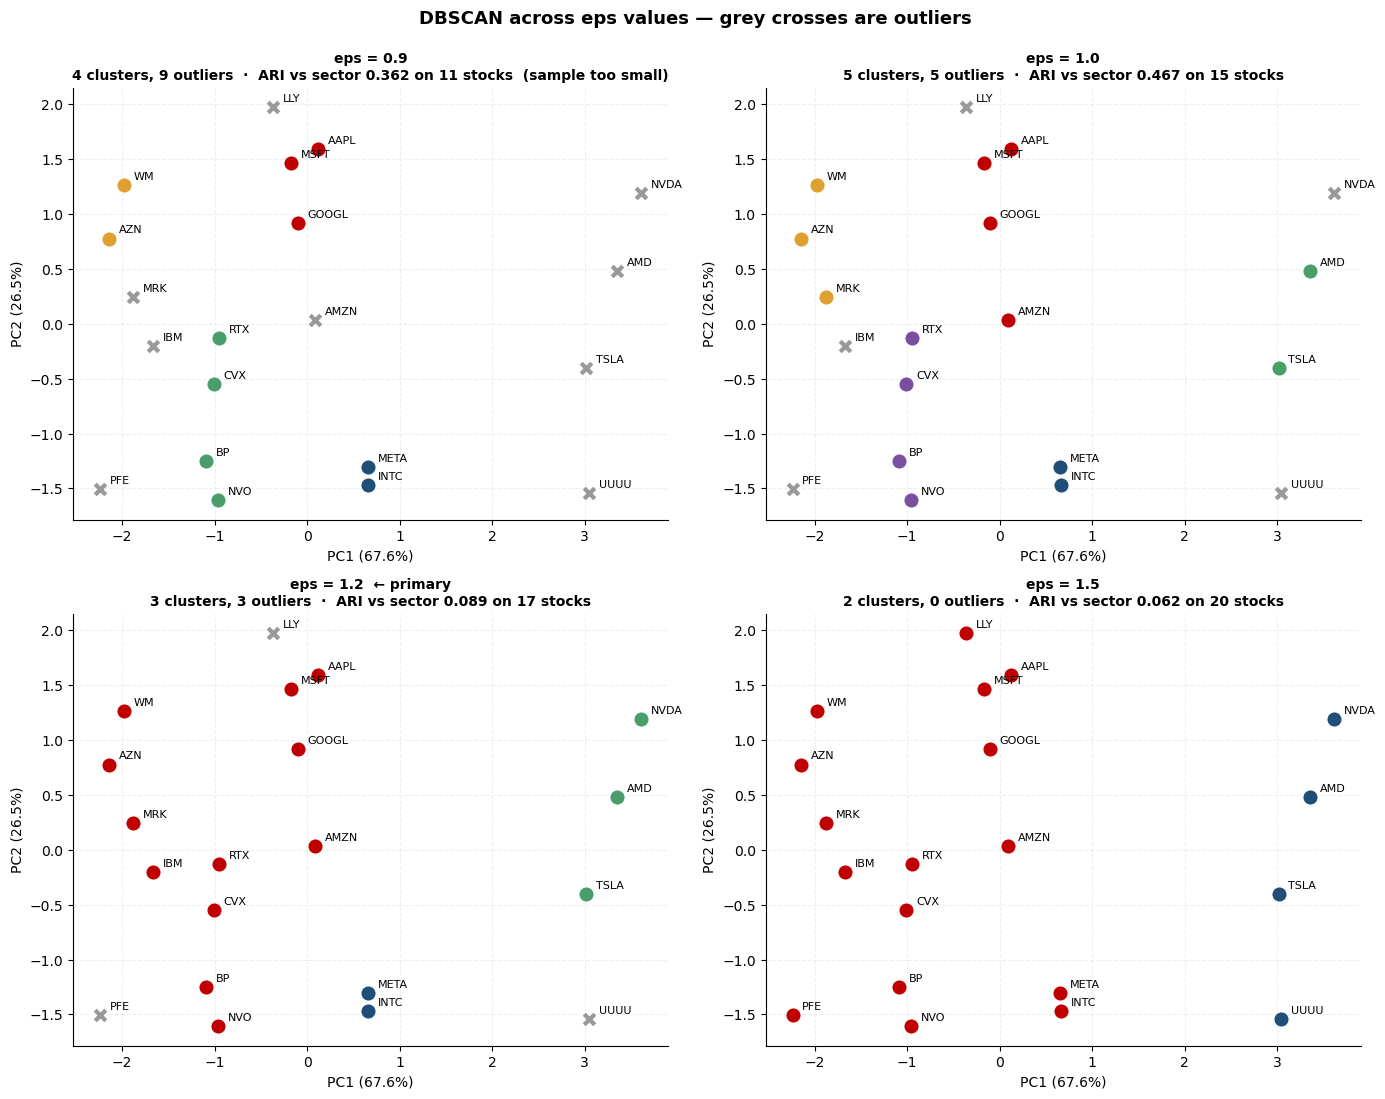

In [29]:
# DBSCAN across eps values 
# lower eps finds more structure but discards more stocks. On the
# settings that retain enough data to interpret, no value recovers
# sector membership.

eps_values = [0.9, 1.0, 1.2, 1.5]

fig, axes = plt.subplots(2, 2, figsize=(14, 11))

for ax, eps in zip(axes.flatten(), eps_values):
    lab     = DBSCAN(eps=eps, min_samples=MIN_SAMPLES).fit_predict(X_scaled.values)
    mask    = lab != -1
    n_clust = len(set(lab[mask]))
    cmap    = {c: CLUSTER_COLOURS[i % len(CLUSTER_COLOURS)]
               for i, c in enumerate(sorted(set(lab) - {-1}))}
    cmap[-1] = "#999999"

    for i, (t, l) in enumerate(zip(TICKERS, lab)):
        ax.scatter(coords[i, 0], coords[i, 1], color=cmap[l], s=120, zorder=3,
                   marker="X" if l == -1 else "o",
                   edgecolors="white", linewidth=0.8)
        ax.annotate(t, (coords[i, 0], coords[i, 1]),
                    textcoords="offset points", xytext=(7, 4), fontsize=8)

    ari  = adjusted_rand_score(np.array(sector_labels)[mask], lab[mask]) \
           if n_clust > 1 else np.nan
    flag = "" if mask.sum() >= 15 else "  (sample too small)"
    star = "  ← primary" if eps == EPS else ""

    ax.set_title(f"eps = {eps}{star}\n{n_clust} clusters, {(~mask).sum()} outliers  ·  "
                 f"ARI vs sector {ari:.3f} on {mask.sum()} stocks{flag}",
                 fontsize=10, fontweight="bold")
    ax.set_xlabel(f"PC1 ({var[0]*100:.1f}%)")
    ax.set_ylabel(f"PC2 ({var[1]*100:.1f}%)")
    ax.grid(color="#e8e8e8", linewidth=0.8, linestyle="--", alpha=0.7)
    ax.set_axisbelow(True)
    for spine in ["top", "right"]:
        ax.spines[spine].set_visible(False)

fig.suptitle("DBSCAN across eps values — grey crosses are outliers",
             fontsize=13, fontweight="bold", y=0.995)
plt.tight_layout()
plt.show()

---
## **Comparison**

Four algorithms with different mechanisms are now compared on three questions:
how well separated their clusters are, how much they agree with each other, and
how closely they correspond to sector membership.

In [30]:
# Assemble all four clusterings 
# each algorithm was run in its own section above; this collects
# the results for a like-for-like comparison. k=4 throughout for
# the partitioning methods, matching the number of sectors being
# tested against. DBSCAN determines its own count.

clusterings = {
    "KMeans":       kmeans_labels,
    "Hierarchical": hier,
    "K-Medoids":    medoid_labels,
    "DBSCAN":       db,
}

print(f"Medoid stocks: {', '.join(medoid_tickers)}\n")
for name, labels in clusterings.items():
    n_clust = len(set(labels) - {-1})
    n_noise = int((labels == -1).sum())
    print(f"{name:14s} {n_clust} clusters"
          + (f", {n_noise} outliers" if n_noise else ""))

Medoid stocks: TSLA, BP, GOOGL, MRK

KMeans         4 clusters
Hierarchical   4 clusters
K-Medoids      4 clusters
DBSCAN         3 clusters, 3 outliers


In [31]:
# Evaluation
# outliers are excluded from all metrics for DBSCAN so that every
# figure is computed on points the algorithm actually assigned

rows = []
for name, labels in clusterings.items():
    mask = labels != -1
    rows.append({
        "Algorithm":      name,
        "Clusters":       len(set(labels[mask])),
        "Stocks scored":  int(mask.sum()),
        "Silhouette":     silhouette_score(Xv[mask], labels[mask]),
        "Davies-Bouldin": davies_bouldin_score(Xv[mask], labels[mask]),
        "ARI vs sector":  adjusted_rand_score(
                              np.array(sector_labels)[mask], labels[mask]),
    })

evaluation = pd.DataFrame(rows).round(3)
print(evaluation.to_string(index=False))
print("\nSilhouette: higher is better. Davies-Bouldin: lower is better.")
print("ARI vs sector: 0 means no relationship, 1 means exact recovery.")

   Algorithm  Clusters  Stocks scored  Silhouette  Davies-Bouldin  ARI vs sector
      KMeans         4             20       0.385           0.748          0.070
Hierarchical         4             20       0.385           0.748          0.070
   K-Medoids         4             20       0.380           0.744          0.152
      DBSCAN         3             17       0.366           0.625          0.089

Silhouette: higher is better. Davies-Bouldin: lower is better.
ARI vs sector: 0 means no relationship, 1 means exact recovery.


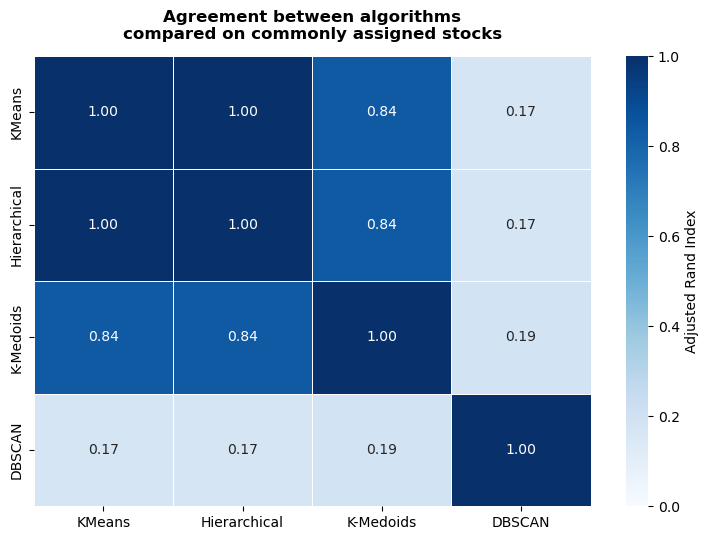

              KMeans  Hierarchical  K-Medoids  DBSCAN
KMeans         1.000         1.000      0.839   0.174
Hierarchical   1.000         1.000      0.839   0.174
K-Medoids      0.839         0.839      1.000   0.190
DBSCAN         0.174         0.174      0.190   1.000


In [32]:
# Do the algorithms agree with each other? 
# ARI is invariant to how clusters are numbered, so no manual
# label alignment is needed. Comparisons involving DBSCAN use only
# the stocks it assigned to a cluster, so outliers are not treated
# as a cluster of their own.

names = list(clusterings)
agree = pd.DataFrame(index=names, columns=names, dtype=float)

for a in names:
    for b in names:
        mask = (clusterings[a] != -1) & (clusterings[b] != -1)
        agree.loc[a, b] = adjusted_rand_score(
            clusterings[a][mask], clusterings[b][mask]
        )

fig, ax = plt.subplots(figsize=(7.5, 5.5))
sns.heatmap(agree.astype(float), annot=True, fmt=".2f", cmap="Blues",
            vmin=0, vmax=1, linewidths=0.5, linecolor="white", ax=ax,
            cbar_kws={"label": "Adjusted Rand Index"})
ax.set_title("Agreement between algorithms\ncompared on commonly assigned stocks",
             fontsize=12, fontweight="bold", pad=12)
plt.tight_layout()
plt.show()

print(agree.round(3).to_string())

The result is consistent across every algorithm.

| Algorithm | Clusters | Silhouette | Davies-Bouldin | ARI vs sector |
| --- | --- | --- | --- | --- |
| K-means | 4 | 0.385 | 0.748 | 0.070 |
| Hierarchical | 4 | 0.385 | 0.748 | 0.070 |
| K-medoids | 4 | 0.380 | 0.744 | 0.152 |
| DBSCAN | 3 | 0.366 | 0.625 | 0.089 |

**No algorithm recovers sector membership.** ARI ranges from 0.062 to 0.152,
against 0 for a random labelling and 1 for exact recovery.

**The algorithms do, however, agree with each other.** K-means and hierarchical
produce identical partitions at ARI 1.00. K-medoids agrees with both at 0.84.
DBSCAN's lower agreement at 0.17 to 0.19 reflects it finding three clusters
rather than four and leaving three stocks unassigned, not a different view of
the structure.

That contrast is the core finding. Four methods with different assumptions
converge on the same grouping, and that grouping is not sector. If the clusters
were arbitrary artefacts of one algorithm's mechanics, the methods would
disagree with each other as well. They do not.

In [33]:
# Membership across all four
# DBSCAN outliers shown as "out"

membership = pd.DataFrame(
    {name: labels for name, labels in clusterings.items()},
    index=TICKERS,
)
membership["DBSCAN"] = membership["DBSCAN"].replace(-1, "out")
membership.insert(0, "Sector", sector_labels)
membership = membership.sort_values(["Sector", "KMeans"])

print(membership.to_string())

           Sector  KMeans  Hierarchical  K-Medoids DBSCAN
AMZN     Big Tech       1             0          2      0
META     Big Tech       1             0          1      1
AAPL     Big Tech       2             2          2      0
GOOGL    Big Tech       2             2          2      0
MSFT     Big Tech       2             2          2      0
TSLA     Chips/EV       0             1          0      2
NVDA     Chips/EV       0             1          0      2
AMD      Chips/EV       0             1          0      2
INTC     Chips/EV       1             0          1      1
IBM      Chips/EV       3             3          3      0
UUUU   Industrial       0             1          0    out
CVX    Industrial       1             0          1      0
BP     Industrial       1             0          1      0
RTX    Industrial       1             0          1      0
WM     Industrial       3             3          3      0
NVO        Pharma       1             0          1      0
PFE        Pha

Reading the membership table by sector makes the point directly. Under k-means:

- **Big Tech** splits across three clusters
- **Chips and EV** splits across four
- **Industrial** splits across four
- **Pharma** splits across four

Not one sector survives as a group. The clusters that do form are coherent on
risk characteristics and indifferent to industry: AAPL, GOOGL, MSFT and LLY
group together on efficient returns with shallow drawdowns; IBM, WM, MRK and AZN
group on low beta and low volatility.

## **5. Conclusion**

### The finding

Sector labels do not describe how these stocks behave. Four clustering
algorithms, applied to five standard risk and return measures over ten years of
daily data, produce groupings that bear almost no relationship to industry
membership - adjusted Rand indices between 0.062 and 0.152, against 0 for random
labelling.

The algorithms agree with each other. K-means and hierarchical clustering
produce identical partitions; k-medoids agrees with both at 0.84. Four methods
with different assumptions converge on the same structure, and that structure is
risk, not industry.

### What the structure actually is

Principal component analysis makes it explicit. Two components capture 93% of
the variance in five features:

**PC1 (66.7%) is market risk exposure.** Return, volatility and beta load almost
equally and positively; drawdown negatively. High values describe stocks that
move hard with the market, deliver high returns and fall deeply.

**PC2 (26.3%) is risk-adjusted quality.** Sharpe ratio and drawdown load
identically at 0.66 while beta is near zero. High values describe efficient
returns without severe losses, independent of how much market risk was taken.

Neither axis corresponds to sector. Pharma spans the full range of PC2, from LLY
at the top to NVO at the bottom. Big Tech spans it too, from MSFT to META.

### Where sector does carry information

One measure suggests sector is not entirely uninformative. The **timing** of
maximum drawdowns clusters by industry: industrials bottomed in March 2020,
technology and semiconductors in late 2022, and every pharmaceutical stock
except AZN recorded its worst drawdown in 2025 or 2026.

So sector membership appears to influence *when* a stock falls, even where it
fails to predict how much risk that stock carries or how efficiently it is
rewarded.

### Limitations

**Twenty stocks is a small sample.** Conclusions about four-stock groups are
necessarily tentative, and one unusual holding - UUUU, a uranium miner with more
than twice the volatility of anything else - exerts substantial influence.

**The sector labels are hand-assigned**, not drawn from a standard
classification such as GICS. Some are deliberately loose. A formal classification
might perform better, though the within-sector variance analysis suggests the
problem is not the labelling scheme: Chips/EV is more internally varied than the
market as a whole regardless of what it is called.

**The features are correlated.** Sharpe ratio is derived from return and
volatility, and return correlates at 0.85 with beta. This reflects the genuine
relationship between risk and reward rather than redundancy alone, but it means
the five measures carry less independent information than their number suggests.

**The ten year window includes COVID.** Only 6 of 20 stocks recorded their worst
drawdown in 2020, so the measure is not dominated by that event, but the period
is unusual.

### Why it matters

Sector classifications are used to construct funds, to assess diversification
and to frame market commentary. If two stocks in the same sector can have betas
of 0.81 and 1.83, and annual returns of 12.5% and 62.2% - as IBM and NVDA do -
then a portfolio diversified by sector may not be diversified by risk at all.